#### 복습
1. YOLO
- 실시간 객체탐지 모델
- 탐지 + 분류 한번에
2. 모델 학습
- 라벨링 : 답지데이터
- data.yaml : 모델 학습에 필요한 정보
3. 이미지 데이터셋 사이트
- Kaggle
- Roboflow
4. 모델 성능 평가
- 탐지(바운딩박스) : IoU
- 분류 : Confidence Score
- 종합성능지표 : mAP

### Image Segmentaion
- 객체를 탐지할 때 Bounding box로 탐지하는 방법을 사용하는 것이 아닌 정확한 픽셀들의 위치와 패턴을 가지고 예측을 진행하는 방법
- 세분화된 탐지 가능

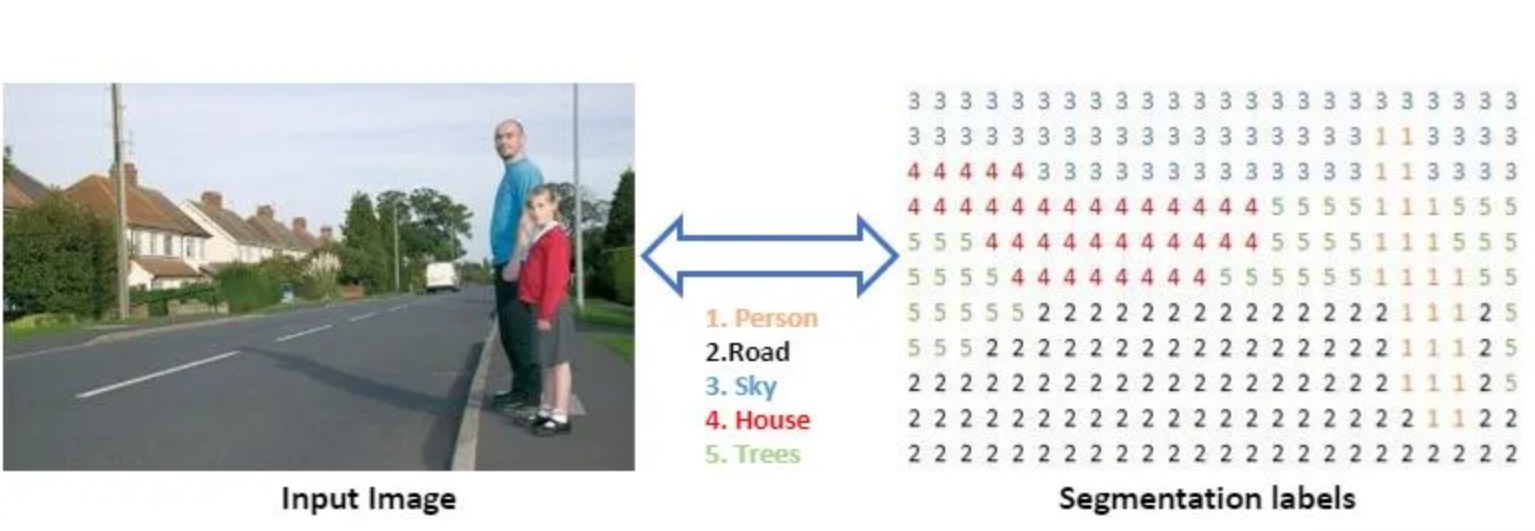

### 차량 파손 데이터를 활용하여 학습을 진행
- Roboflow에서 다른 사람들이 공개한 데이터셋을 활용하여 YOLO26n-seg 모델 학습
- https://universe.roboflow.com/none-n1imd/car-jxbzt/dataset/1

In [ ]:
# 드라이브 마운트
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive/2026_목포대학교_vision

/content/drive/MyDrive/2026_목포대학교_vision


In [3]:
# 데이터셋 다운로드
!pip install roboflow # 세션 다시시작 주의!

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 66.5 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]


#### 학습을 진행한 모델 불러와서 사용
- 우리가 학습을 진행한 best.pt를 가져와 사용하기
- segmentation 실습

In [4]:
from roboflow import Roboflow
rf = Roboflow(api_key="0jfm6qYY1tHtRzICFWQV")
project = rf.workspace("none-n1imd").project("car-jxbzt")
version = project.version(1)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to car-1 in yolo26:: 100%|██████████| 671/671 [00:05<00:00, 127.27it/s]


In [6]:
# 도구 설치하기
!pip install ultralytics opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [7]:
# 도구 불러오기

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [8]:
# 사전학습된 모델 다운로드
model = YOLO('./data/yolo26n-seg.pt')

In [9]:
# 모델학습
results = model.train(
            # 사용할 데이터
            data = '/content/drive/MyDrive/2026_목포대학교_vision/car-1/data.yaml',
            # 학습횟수 지정
            epochs= 50,
            # 이미지 사이즈
            imgsz = 640,
            # batch 사이즈
            batch = 16,
            # 10번동안 개선이 없을 경우 학습을 종료
            patience = 10
          )

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/2026_목포대학교_vision/car-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=./data/yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64,

In [10]:
# 베스트 모델 불러오기
seg_model = YOLO('./runs/segment/train/weights/best.pt')

In [13]:
# 예측진행
result = seg_model.predict('./data/car_damage.jpeg', conf=0.2)   # 기본: 0.25


image 1/1 /content/drive/MyDrive/2026_목포대학교_vision/data/car_damage.jpeg: 448x640 2 front_headlight_damages, 1 scratch, 1 tail_light_damage, 16.6ms
Speed: 2.1ms preprocess, 16.6ms inference, 13.1ms postprocess per image at shape (1, 3, 448, 640)


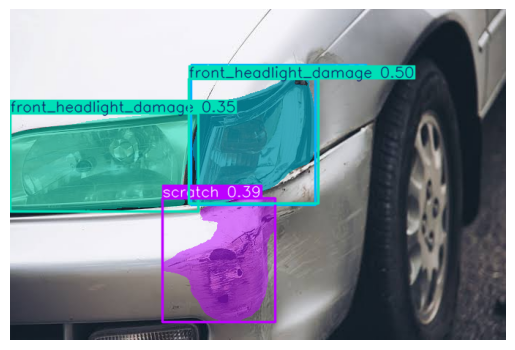

In [14]:
# 시각화
img = result[0].plot()

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis('off')
plt.show()

In [18]:
# 베스트 모델 불러오기
nail_model = YOLO('/content/drive/MyDrive/2026_목포대학교_vision/best(nail)_seg.pt')

In [19]:
# 예측진행
result = nail_model.predict('./data/nail.jpg', conf=0.2)   # 기본: 0.25


image 1/1 /content/drive/MyDrive/2026_목포대학교_vision/data/nail.jpg: 352x640 10 Nails, 9.8ms
Speed: 1.8ms preprocess, 9.8ms inference, 2.5ms postprocess per image at shape (1, 3, 352, 640)


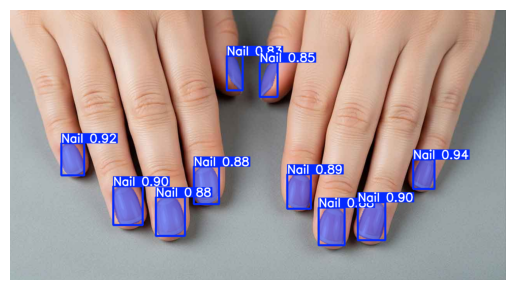

In [20]:
# 시각화
img = result[0].plot()

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis('off')
plt.show()